# PASSAGE Display
Browse local samples under `outputs/dataset` by resolution and split, then render tensors, paths, and optional PNGs. Set `RESOLUTION`, `SPLIT`, and `SAMPLE_INDEX` (or leave `None` to auto-pick the first available).

In [1]:
from pathlib import Path
from typing import Iterable
import sys

import matplotlib.pyplot as plt
import numpy as np
import yaml

# Allow importing project modules
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC_ROOT = ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

In [2]:
from passage.visualization import tensor_to_image
from passage.utils import load_tensor, TENSOR_SUFFIX
from passage.export import parse_path_csv

/shared/home/geoffrey.delhomme.e/projects/PASSAGE/passage/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Parameters (papermill)
RESOLUTION = 512
SPLIT = "train"
SAMPLE_INDEX = None

In [4]:
def load_tensor_compat(path: Path, resolution: int) -> np.ndarray:
    """Load a tensor from either compressed (.npy.zst/.zst) or legacy (.npy) format.

    Prefer `passage.utils.load_tensor` if available. If not, attempt to
    decompress `.npy.zst` files using `zstandard` and fall back to `np.load`.
    """
    # Use project-provided loader when available
    if load_tensor is not None and (path.suffix == ".zst" or str(path).endswith(TENSOR_SUFFIX)):
        return load_tensor(path, (resolution, resolution, 3), "float32")

    # Fallback: handle .npy.zst or .zst by decompressing with zstandard if available
    if path.suffix == ".zst" or str(path).endswith(TENSOR_SUFFIX):
        try:
            import io
            import zstandard as zstd

            with open(path, "rb") as f:
                dctx = zstd.ZstdDecompressor()
                decompressed = dctx.decompress(f.read())
                return np.load(io.BytesIO(decompressed))
        except Exception:
            # Let numpy try (will raise if unsupported)
            return np.load(path)

    # Regular numpy files
    return np.load(path)


DATASET_ROOT = ROOT / "outputs" / "dataset"


def paths_from_metadata(meta: dict, key: str) -> list[tuple[int, int]]:
    node = (meta.get("paths") or {}).get(key, {})
    pixels = node.get("pixels") or []
    coords: list[tuple[int, int]] = []
    for p in pixels:
        if isinstance(p, dict) and "i" in p and "j" in p:
            coords.append((int(p["i"]), int(p["j"])))
    return coords


def to_array(path_list: Iterable[Iterable[int]] | None) -> np.ndarray | None:
    """Convert an iterable of (i,j) pairs into a numpy array or return None."""
    if not path_list:
        return None
    arr = np.asarray(list(path_list), dtype=int)
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)
    return arr


def find_sample_paths(resolution: int, split: str, sample_index: int | None) -> dict | None:
    """Find sample file paths for a given resolution/split and optional index.

    Supports both YAML and JSON metadata files. Returns a dict with keys:
    metadata_path, tensor_path, image_path, path_free_csv, path_obstacles_csv
    or None if no sample found.
    """
    base = DATASET_ROOT / str(resolution) / split
    metadata_dir = base / "metadata"
    if not metadata_dir.exists():
        return None

    # Support both .yaml and .json metadata files
    metas = (
        sorted(metadata_dir.rglob("*.yaml"))
        + sorted(metadata_dir.rglob("*.yml"))
        + sorted(metadata_dir.rglob("*.json"))
    )
    if not metas:
        return None

    # If sample_index not provided, pick the first; otherwise validate index
    if sample_index is None:
        meta_path = metas[0]
    else:
        if sample_index < 0 or sample_index >= len(metas):
            return None
        meta_path = metas[sample_index]

    lat_dir = meta_path.parent.parent.name
    lon_dir = meta_path.parent.name
    stem = meta_path.stem

    tensors_dir = base / "tensors" / lat_dir / lon_dir
    tensor_zst = tensors_dir / f"{stem}.npy.zst"
    tensor_npy = tensors_dir / f"{stem}.npy"
    tensor_path = tensor_zst if tensor_zst.exists() else tensor_npy

    return {
        "metadata_path": meta_path,
        "tensor_path": tensor_path,
        "image_path": base / "images" / lat_dir / lon_dir / f"{stem}.png",
        "path_free_csv": base / "paths" / "free" / lat_dir / lon_dir / f"{stem}.csv",
        "path_obstacles_csv": base / "paths" / "obstacles" / lat_dir / lon_dir / f"{stem}.csv",
    }


def summarize(meta: dict) -> str:
    res = meta.get("resolution")
    split = meta.get("split")
    target_elev = meta.get("target_elevation")
    free_len = (meta.get("paths") or {}).get("without_obstacles", {}).get("length")
    obs_len = (meta.get("paths") or {}).get("with_obstacles", {}).get("length")
    parts = [f"resolution={res}" if res is not None else "", f"split={split}" if split else ""]
    desc = " ".join([p for p in parts if p])
    if target_elev is not None:
        desc += f", target_elevation={target_elev:.1f}"
    if free_len is not None or obs_len is not None:
        desc += f" | path len free={free_len}, obstacles={obs_len}"
    return desc.strip()

In [5]:
paths = find_sample_paths(RESOLUTION, SPLIT, SAMPLE_INDEX)
tensor = None
image = None
metadata = {}
path_free = None
path_obstacles = None

if not paths:
    print(f"No sample found for resolution={RESOLUTION}, split={SPLIT}, index={SAMPLE_INDEX}")
else:
    metadata = yaml.safe_load(paths["metadata_path"].read_text()) or {}
    print(f"Using metadata: {paths['metadata_path']}")
    tensor_path = paths["tensor_path"]
    if tensor_path.exists():
        tensor = load_tensor_compat(tensor_path, RESOLUTION)
    image_path = paths["image_path"]
    if image_path.exists():
        image = plt.imread(image_path)
    path_free = paths_from_metadata(metadata, "without_obstacles")
    path_obstacles = paths_from_metadata(metadata, "with_obstacles")
    if not path_free and paths["path_free_csv"].exists():
        path_free = parse_path_csv(paths["path_free_csv"])
    if not path_obstacles and paths["path_obstacles_csv"].exists():
        path_obstacles = parse_path_csv(paths["path_obstacles_csv"])
    path_free = to_array(path_free)
    path_obstacles = to_array(path_obstacles)
    print(
        f"tensor shape={getattr(tensor, 'shape', None)}, image={'yes' if image is not None else 'no'}, "
        f"path_free={path_free.shape[0] if path_free is not None else 0}, "
        f"path_obstacles={path_obstacles.shape[0] if path_obstacles is not None else 0}",
    )
    if metadata:
        print(summarize(metadata))

Using metadata: /shared/home/geoffrey.delhomme.e/projects/PASSAGE/passage/outputs/dataset/512/train/metadata/N029/E081/0000000001.yaml
tensor shape=(512, 512, 3), image=yes, path_free=493, path_obstacles=493
resolution=512 split=train, target_elevation=6572.4 | path len free=493, obstacles=493


2026-01-26 07:59:08.438 | DEBUG    | passage.visualization:tensor_to_image:52 - tensor_to_image: elevation BEFORE normalization: min=0.3277, max=0.8198
2026-01-26 07:59:08.442 | DEBUG    | passage.visualization:tensor_to_image:98 - tensor_to_image: elevation AFTER normalization: min=0.0000, max=1.0000
2026-01-26 07:59:08.459 | DEBUG    | passage.visualization:tensor_to_image:134 - tensor_to_image: obst_count=%d, path_count=%d, start_count=%d, end_count=%d


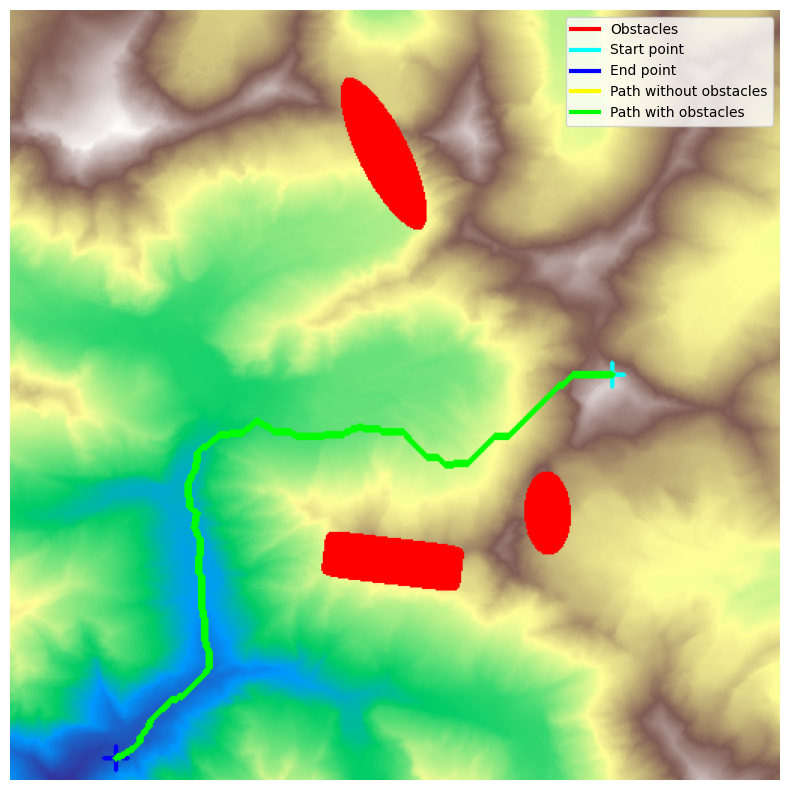

In [6]:
if tensor is not None:
    from matplotlib.lines import Line2D

    path_free_list = None if path_free is None else [tuple(p) for p in path_free.tolist()]
    path_obstacles_list = None if path_obstacles is None else [tuple(p) for p in path_obstacles.tolist()]
    vis_bgr = tensor_to_image(tensor, path_pixels=path_free_list, alt_path_pixels=path_obstacles_list)
    vis_rgb = vis_bgr[:, :, ::-1]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(vis_rgb)
    # ax.set_title("PASSAGE sample visualizatio")
    ax.axis("off")

    legend_handles = [
        Line2D([0], [0], color="#ff0000", lw=3, label="Obstacles"),
        Line2D([0], [0], color="#00ffff", lw=3, label="Start point"),
        Line2D([0], [0], color="#0000ff", lw=3, label="End point"),
        Line2D([0], [0], color="#ffff00", lw=3, label="Path without obstacles"),
        Line2D([0], [0], color="#00ff00", lw=3, label="Path with obstacles"),
    ]
    ax.legend(handles=legend_handles, loc="upper right", frameon=True)

    plt.tight_layout()
    plt.show()
else:
    print("Tensor missing; check the configuration above.")